[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Notebooks/solutions/ReactorsParameterEstimation_solution.ipynb)

In [1]:
# Solution notebooks live in solutions/. They run from the parent folder,
# where data/ and workshop_utils.py are. (This cell is not in the student version.)
import os
import sys

if os.path.basename(os.getcwd()) == 'solutions':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

# Parameter estimation for a batch reactor

## Contextualization

This notebook shows how to set up a reactor model with PharmaPy and how to fit its kinetic parameters to data with `scipy.optimize.minimize`. It focuses on multiple reactions in a batch reactor:

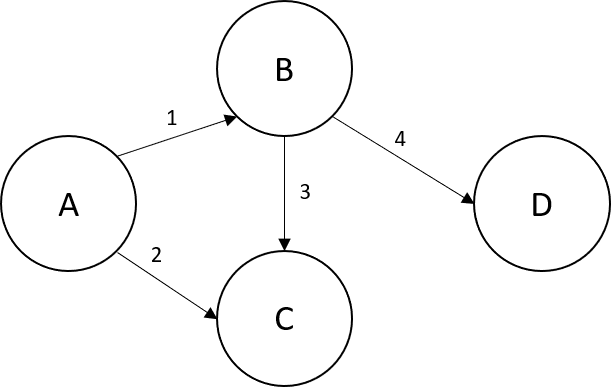

## Reactor model
The batch reactor model solved by PharmaPy for this problem is a system of ordinary differential equations (ODEs):

$$ \frac{dC_j}{dt} = \sum_{i=1}^4 \nu_{i, j} r_i \quad \forall j \in \{A, B, C, D\} \tag{1} $$

with reaction rates given by:

$$ r_i = k_i \prod_{k \in \mathcal{R}_i} C_k^{\alpha_{i,k}}, \quad \forall i \in \{1, 2, 3, 4\} \tag{2} $$

where $\mathcal{R_i}$ is the set of reactants of reaction $i$ (e.g. $\mathcal{R}_3 = \{B\}$). The temperature-dependent coefficient $k_i$ is given by an Arrhenius expression:

$$ k_i = A_i \exp \left[-\frac{E_i}{RT} \right], \quad \forall i \in \{1, 2, 3, 4\} \tag{3} $$

Simulating a batch reactor in PharmaPy requires four objects:

1. **Integrator backend**: the ODE solver that the unit owns. We use `ScipyBackend`, which wraps `scipy.integrate.solve_ivp` and needs nothing beyond scipy (`AssimuloBackend` is a faster alternative if Assimulo is installed). Every unit gets its *own* backend instance.
2. **Reactor**: the unit operation model, Eq. (1) (`BatchReactor`)
3. **Phase**: the initial liquid load in the reactor (`LiquidPhase`)
4. **Kinetics**: reaction rate parameters and rate calculations, Eqs. (2)-(3) (`RxnKinetics`)

The reactor is created first, then the phase is loaded into it, and the kinetics come last.

First, the corresponding PharmaPy classes are imported:

**Running on Google Colab?** Run the next cell first. It installs PharmaPy and puts this notebook's data files and `workshop_utils.py` on the Colab machine (about half a minute). Run it again whenever the runtime restarts. To keep your work, use *File → Save a copy in Drive*. On your own computer the cell skips the install and only unpacks the files.

In [ ]:
# @title Colab setup: run this cell first { display-mode: "form" }
# Installs PharmaPy and unpacks workshop_utils.py and data/ into the working
# directory. Run it again after a runtime restart or a factory reset.
import base64, importlib.metadata, importlib.util, io, os, subprocess, sys, zipfile

if 'google.colab' in sys.modules or importlib.util.find_spec('PharmaPy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pharmapy-org>=0.3.1'], check=True)

_FILES = (
    '...'
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_FILES))) as archive:
    archive.extractall('.')
importlib.invalidate_caches()

try:
    _version = importlib.metadata.version('pharmapy-org')
except importlib.metadata.PackageNotFoundError:   # a development install of PharmaPy
    _version = '(development install)'
print('PharmaPy', _version, '- workshop files ready in', os.getcwd())

In [2]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PharmaPy.Phases_Refactored import LiquidPhase
from PharmaPy.Kinetics import RxnKinetics
from PharmaPy.Reactors_Refactored import BatchReactor
from PharmaPy.IntegratorBackends import ScipyBackend

A liquid phase needs the path to a property file with pure-component information for all the chemical species (`path_pure`). The file has 5 species (A, B, C, D and solvent), so composition vectors have size 5. A phase also needs an **amount**; here we load 1 L (`vol=1e-3` m$^3$).

The reaction kinetics receives the same `json` file and the reaction network as a list of strings, which PharmaPy uses to build the stoichiometric matrix. $T_{ref}$ in Eq. (3) is not passed to `RxnKinetics`, so PharmaPy uses the non-centered Arrhenius form.

The reactor is created with its own integrator backend. `isothermal=True` keeps the temperature at the value of the liquid phase (no energy balance is solved).

In [3]:
path_pure = 'data/pure_components_ziegler.json'

reactor = BatchReactor(integrator=ScipyBackend(), isothermal=True)  # [blank] create an isothermal BatchReactor with its own ScipyBackend()

liquid = LiquidPhase(path_pure, temp=673, mole_conc=[1, 0, 0, 0, 0], vol=1e-3, name_solv='solvent')  # [adv] 1 L of liquid at 673 K with C_A = 1 mol/L (mole_conc=[1, 0, 0, 0, 0], name_solv='solvent')

rxns = ['A --> B', 'A --> C', 'B --> C', 'B --> D']
k_vals = [0.1] * 4
ea_vals = [0] * 4
kin = RxnKinetics(path_pure, rxn_list=rxns, k_params=k_vals, ea_params=ea_vals)  # [adv] RxnKinetics for 'rxns' with k_params=k_vals and ea_params=ea_vals

Once the phase and kinetic objects are created, they are aggregated to the reactor using the dot syntax. **Order matters**: `RxnKinetics` wires the reactions to the liquid phase, so the phases must be set first.

In [4]:
reactor.Phases = liquid  # [adv] load the liquid into the reactor
reactor.RxnKinetics = kin  # [blank] attach the kinetics (after the phases!)

Now the reactor model can be solved in standalone mode. `solve_unit` returns the time vector and the solver states. For the reactor, the states are the **species masses** (kg), not concentrations; concentrations and other derived quantities are stored in the `result` object.

In [5]:
time_sim, states = reactor.solve_unit(runtime=120, verbose=False)  # [adv] solve the reactor for 2 minutes (runtime=120, verbose=False)

print(reactor.result)

------------------------
PharmaPy result object
------------------------

Fields shown in the tables below can be accessed as result.<field>, e.g. result.mass_j_liquid0 

---------------------------------------------------
states           dim   units   index                  
---------------------------------------------------
mass_j_liquid0   5     kg      A, B, C, D, solvent    
---------------------------------------------------

----------------------------------------------------------
f(states)           dim   units       index                  
----------------------------------------------------------
Total_m_in_vessel   1     kg/s                               
vessel_vol          1     m3                                 
global_temp         1     K                                  
mole_conc_liquid0   5     kmol/m3     A, B, C, D, solvent    
----------------------------------------------------------

Time vector can be accessed as result.time



Any field of `result` can be plotted directly:

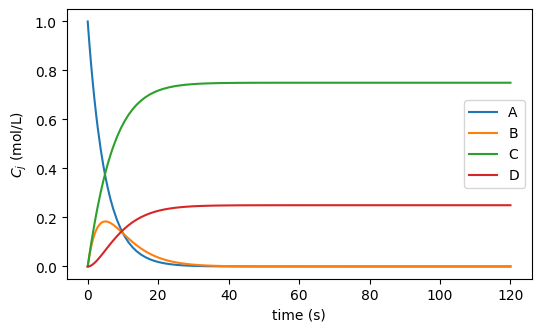

In [6]:
res = reactor.result

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(res.time, res.mole_conc_liquid0[:, :4])
ax.legend(['A', 'B', 'C', 'D'])
ax.set_xlabel('time (s)')
ax.set_ylabel('$C_j$ (mol/L)')
plt.show()

### A simulation function and local sensitivities

For parameter estimation we will call the model many times, so it is convenient to wrap the simulation in a function. Three details matter here:

* A new reactor (and integrator) is built for every call. Calling `solve_unit` twice on the same object *continues* the integration from where it stopped.
* `solve_unit(time_grid=...)` needs strictly increasing times. Some datasets contain replicate samples (repeated times), so we solve on the unique times and interpolate back.
* `ScipyBackend(method='LSODA', ...)` selects the `solve_ivp` method. LSODA is fast for this small, mildly stiff system. Tight tolerances make the finite-difference gradients used by the optimizer accurate.

The local sensitivities $\mathbf{S}(t) \equiv \partial C_j / \partial \theta_p$ tell us which parameters the measurements can inform. `ScipyBackend` does not compute them, but we can approximate them by **finite differences**: perturb one parameter, re-simulate, and take the difference.

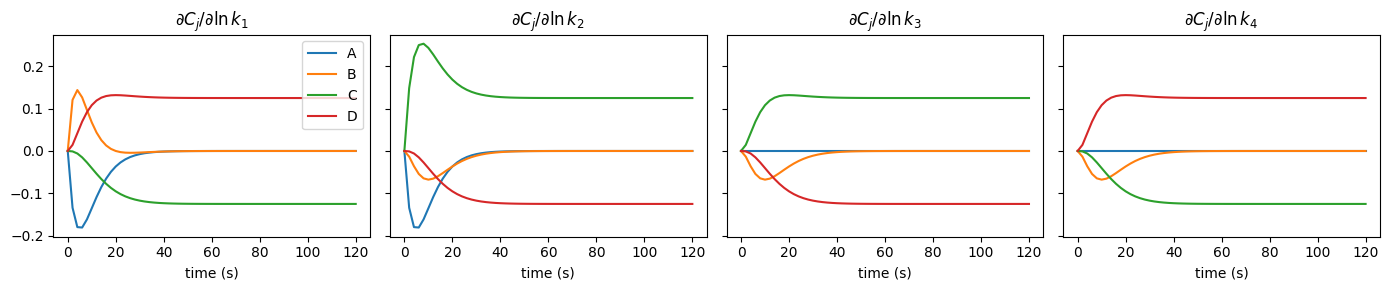

In [7]:
def simulate(kinetics, t_vals, temp, conc_init):
    """Isothermal batch reactor. Returns concentrations (mol/L) at t_vals, one column per species."""
    # [adv-start] build a new isothermal BatchReactor (ScipyBackend(method='LSODA', options={'atol': 1e-10, 'rtol': 1e-8})), load a 1 L liquid at 'temp' with 'conc_init', attach 'kinetics' and solve on np.unique(t_vals)
    reactor = BatchReactor(integrator=ScipyBackend(method='LSODA', options={'atol': 1e-10, 'rtol': 1e-8}),
                           isothermal=True)
    reactor.Phases = LiquidPhase(path_pure, temp=temp, mole_conc=conc_init, vol=1e-3, name_solv='solvent')  # [blank] liquid at 'temp' with concentrations 'conc_init' (1 L, name_solv='solvent')
    reactor.RxnKinetics = kinetics

    reactor.solve_unit(time_grid=np.unique(t_vals), verbose=False)
    # [adv-end]

    res = reactor.result
    return np.column_stack([np.interp(t_vals, res.time, conc) for conc in res.mole_conc_liquid0.T])


# Finite-difference sensitivities with respect to ln(k_i)
t_grid = np.linspace(0, 120, 61)
ln_k = np.log(k_vals)
d_ln_k = 1e-4

conc_base = simulate(RxnKinetics(path_pure, rxn_list=rxns, k_params=np.exp(ln_k), ea_params=ea_vals),
                     t_grid, 673, [1, 0, 0, 0, 0])

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ind, ax in enumerate(axes):
    ln_k_pert = ln_k.copy()
    ln_k_pert[ind] += d_ln_k

    kin_pert = RxnKinetics(path_pure, rxn_list=rxns, k_params=np.exp(ln_k_pert), ea_params=ea_vals)  # [adv] kinetics with k_params = exp(ln_k_pert)
    conc_pert = simulate(kin_pert, t_grid, 673, [1, 0, 0, 0, 0])

    ax.plot(t_grid, (conc_pert - conc_base)[:, :4] / d_ln_k)
    ax.set_title(r'$\partial C_j / \partial \ln k_%i$' % (ind + 1))
    ax.set_xlabel('time (s)')

axes[0].legend(['A', 'B', 'C', 'D'])
fig.tight_layout()
plt.show()

## Parameter estimation procedure
The goal is to determine the reaction parameters $A_i$ and $E_i$ ($i = 1, \dots, 4$). Time-dependent $B$ and $C$ concentration datasets are available at different temperatures. We minimize the sum of squared errors between the measured and predicted concentrations:

$$ \min_{\theta} \; SSE(\theta) = \sum_{e} \sum_{t} \sum_{j \in \{B, C\}} \left( C_{j}^{data}(t) - C_{j}^{model}(t; \theta) \right)^2 $$

The approach has two stages. In the first stage, parameters are estimated for each isothermal dataset individually. These estimates are then used as seeds in the second stage, where all the datasets are used simultaneously to obtain representative parameter estimates and confidence intervals.

### First stage: isothermal fitting
Each isothermal dataset only informs $k_i$ at that temperature, so in this stage we estimate $\ln(k_i)$ (working with logarithms keeps all parameters of order one). $E_i$ are obtained afterwards by linear regression of $\ln(k_i)$ vs $1/T$.

As a sanity check, one dataset can be plotted:

(14,) (14, 2)


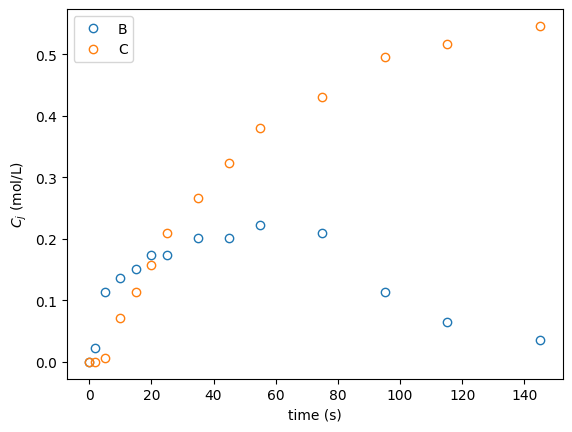

In [8]:
data = np.genfromtxt('data/ziegler_data_673K.csv', delimiter=',')
t_exp = data[:, 0]
c_exp = data[:, 1:]

print(t_exp.shape, c_exp.shape)

plt.plot(t_exp, c_exp, 'o', mfc='None')
plt.xlabel('time (s)')
plt.ylabel('$C_j$ (mol/L)')
plt.legend(('B', 'C'))
plt.show()

We use `scipy.optimize.minimize` directly. It needs:

* an **objective function** `f(params) -> float`, here the SSE. Extra inputs (temperature, initial concentrations, data) are passed with `args=(...)`;
* a **seed** (initial guess) for the parameters;
* a **method**. `L-BFGS-B` is a quasi-Newton method. Since we give no gradient, it estimates it by finite differences with step `eps`. That is why the simulation uses tight tolerances.
* **bounds**: we keep each $\ln k_i$ in $[-12, 3]$. Without them, the first quasi-Newton steps can jump to huge rate constants, which make the ODEs very stiff and the simulations very slow.

The model predicts all 5 species; the data contain only B and C (model columns 1 and 2).

In [9]:
from scipy.optimize import minimize

# Initial concentrations of each experiment
with open('data/ziegler_conc_init.json') as f:
    c_init = json.load(f)

LNK_BOUNDS = [(-12, 3)] * 4   # bounds on ln(k_i)


def sse_isothermal(ln_k, t_exp, c_exp, temp, conc_init):
    """Sum of squared errors of one isothermal experiment, parametrized by ln(k_i)."""
    kin = RxnKinetics(path_pure, rxn_list=rxns, k_params=np.exp(ln_k), ea_params=ea_vals)  # [blank] RxnKinetics with k_params = exp(ln_k) and ea_params = ea_vals
    c_model = simulate(kin, t_exp, temp, conc_init)  # [adv] model concentrations at the measured times
    residuals = c_model[:, [1, 2]] - c_exp  # [blank] model minus data, for B and C only
    return np.sum(residuals**2)


param_seed = np.log(k_vals)
names_lnk = [r'ln k_%i' % (ind + 1) for ind in range(4)]

# [adv-start] minimize sse_isothermal from param_seed with L-BFGS-B (args=(t_exp, c_exp, 673, c_init['673K']), bounds=LNK_BOUNDS, options={'eps': 1e-6}); store it in 'result'
result = minimize(sse_isothermal, param_seed, args=(t_exp, c_exp, 673, c_init['673K']),
                  method='L-BFGS-B', bounds=LNK_BOUNDS, options={'eps': 1e-6})
# [adv-end]

print(result.message)
print('SSE: %.4e after %i model evaluations' % (result.fun, result.nfev))
print(pd.Series(result.x, index=names_lnk))

CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
SSE: 9.8266e-03 after 115 model evaluations
ln k_1   -4.165372
ln k_2   -4.726377
ln k_3   -4.599300
ln k_4   -3.997502
dtype: float64


Data vs model prediction can be plotted to inspect the quality of the fit. The prediction with the seed parameters is included for comparison.

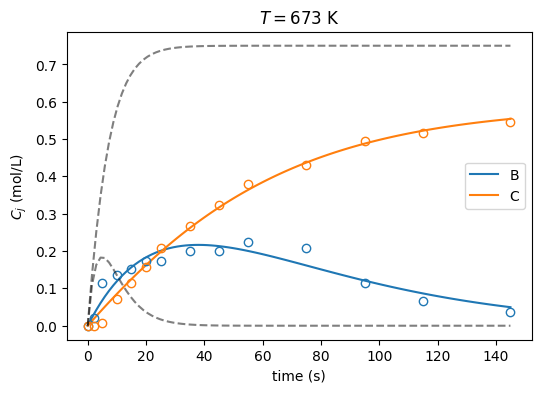

In [10]:
def plot_fit(t_exp, c_exp, kinetics, temp, conc_init, ax, seed_kinetics=None):
    t_fine = np.linspace(0, t_exp[-1], 100)
    c_model = simulate(kinetics, t_fine, temp, conc_init)
    lines = ax.plot(t_fine, c_model[:, [1, 2]])
    for line, measured in zip(lines, c_exp.T):
        ax.plot(t_exp, measured, 'o', mfc='None', color=line.get_color())
    if seed_kinetics is not None:
        ax.plot(t_fine, simulate(seed_kinetics, t_fine, temp, conc_init)[:, [1, 2]], 'k--', alpha=0.5)
    ax.legend(lines, ['B', 'C'])
    ax.set_xlabel('time (s)')
    ax.set_ylabel('$C_j$ (mol/L)')
    ax.set_title('$T = %i$ K' % temp)


fig, ax = plt.subplots(figsize=(6, 4))
plot_fit(t_exp, c_exp, RxnKinetics(path_pure, rxn_list=rxns, k_params=np.exp(result.x), ea_params=ea_vals),
         673, c_init['673K'], ax,
         seed_kinetics=RxnKinetics(path_pure, rxn_list=rxns, k_params=k_vals, ea_params=ea_vals))
plt.show()

Now let's estimate the parameters for all the available datasets, one at a time. The datasets are stored as `data/ziegler_data_XK.csv`, where X is the temperature in K. We use the string formatting syntax `'name_%i' % val` (e.g. if `val = 300`, the result is `'name_300'`).

673 K: SSE 9.827e-03, 115 model evaluations, 2.3 s


698 K: SSE 3.276e-02, 70 model evaluations, 1.3 s


723 K: SSE 5.103e-02, 85 model evaluations, 1.2 s


748 K: SSE 4.722e-02, 155 model evaluations, 2.9 s


773 K: SSE 2.088e-02, 155 model evaluations, 2.7 s


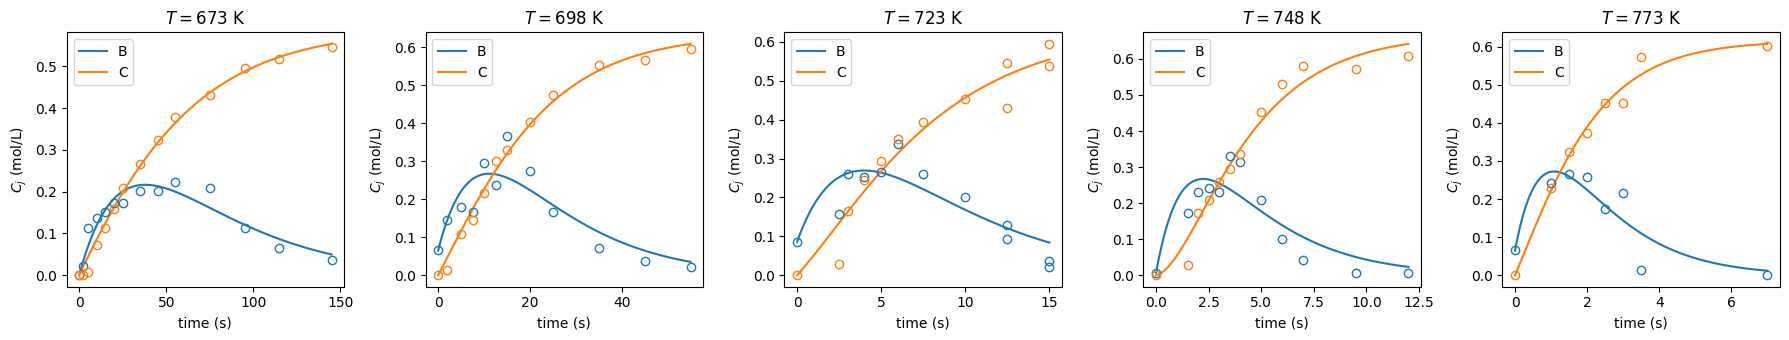

In [11]:
temps = np.array([673, 698, 723, 748, 773])  # available temperatures

lnk_estimated = {}

fig, axes = plt.subplots(1, len(temps), figsize=(18, 3.5))
for temp, ax in zip(temps, axes):
    tic = time.perf_counter()
    data = np.genfromtxt('data/ziegler_data_%iK.csv' % temp, delimiter=',')
    t_exp = data[:, 0]  # [blank] extract the first column from 'data'
    c_exp = data[:, 1:]  # [blank] extract all columns from the second one on
    conc_init = c_init['%iK' % temp]

    # [blank-start] minimize sse_isothermal for this dataset (same seed, method, bounds and options as above) and store the solution in 'result'
    result = minimize(sse_isothermal, param_seed, args=(t_exp, c_exp, temp, conc_init),
                      method='L-BFGS-B', bounds=LNK_BOUNDS, options={'eps': 1e-6})
    # [blank-end]
    lnk_estimated[temp] = result.x
    print('%i K: SSE %.3e, %i model evaluations, %.1f s' % (temp, result.fun, result.nfev, time.perf_counter() - tic))

    plot_fit(t_exp, c_exp, RxnKinetics(path_pure, rxn_list=rxns, k_params=np.exp(result.x), ea_params=ea_vals),
             temp, conc_init, ax)

fig.tight_layout()
plt.show()

The estimates collected in the dictionary `lnk_estimated` can be stacked in a pandas dataframe:

In [12]:
param_summary = pd.DataFrame.from_dict(lnk_estimated, orient='index', columns=names_lnk)
print(param_summary)

       ln k_1    ln k_2    ln k_3    ln k_4
673 -4.165372 -4.726377 -4.599300 -3.997502
698 -2.863818 -3.829622 -3.167063 -3.195270
723 -1.863292 -3.221884 -2.018070 -2.208932
748 -1.121232 -4.677187 -0.971917 -1.632738
773 -0.510277 -1.558614 -0.865224 -0.834009


The linearized form of Eq. (3)

$$ \ln(k_i) = \ln(A_i) - \frac{E_i}{R} \left( \frac{1}{T} \right)$$

allows finding estimates of the pre-exponential factors $A_i$ and activation energies $E_i$ by linear regression of $\ln(k_i)$ vs $1/T$. The plots of data vs the linear model show the quality of the first stage.

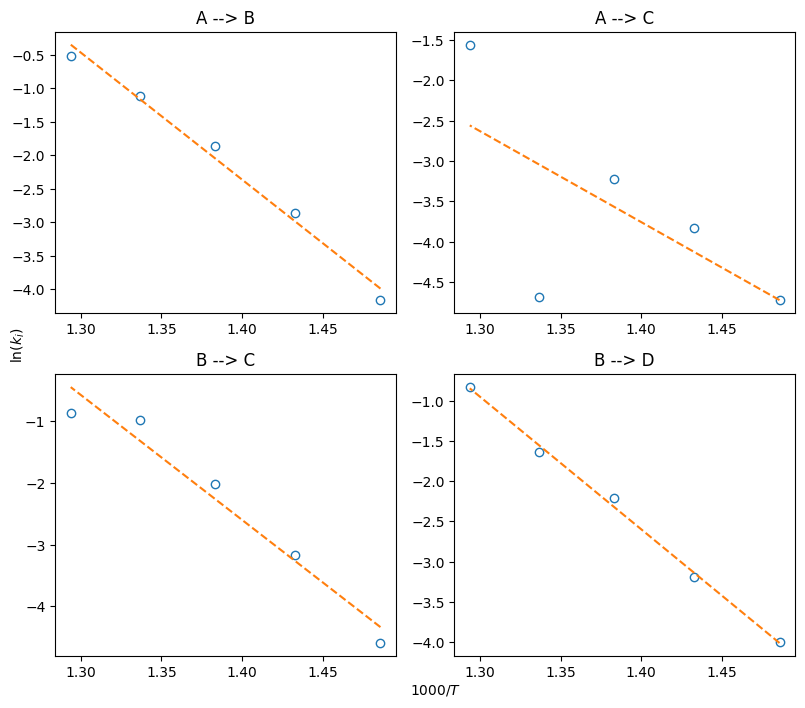

In [13]:
from scipy.stats import linregress


def linear_model(x, sl, interc): return sl * x + interc


ln_A = []
Ea_R = []

fig_lin, ax_lin = plt.subplots(2, 2, figsize=(8, 7))
ax_flat = ax_lin.flatten()
for ind, col in enumerate(param_summary.values.T):
    x = 1 / temps
    y = col
    res = linregress(x, y)  # [blank] call 'linregress' with x and y

    ln_A.append(res.intercept)  # [adv] the intercept is ln(A_i)
    Ea_R.append(-res.slope)  # [adv] minus the slope is E_i / R

    ax = ax_flat[ind]
    ax.plot(1000 * x, y, 'o', mfc='None')  # data
    ax.plot(1000 * x, linear_model(x, res.slope, res.intercept), '--')
    ax.set_title(rxns[ind])

fig_lin.text(0, 0.5, r'$\ln(k_i)$', rotation=90, va='center')
fig_lin.text(0.5, 0, '$1000/T$')
fig_lin.tight_layout()
plt.show()

In [14]:
seed_linear = pd.DataFrame({'ln_A': ln_A, 'Ea/R': Ea_R}, index=rxns)
print(seed_linear)

              ln_A          Ea/R
A --> B  24.152432  18938.504933
A --> C  11.997522  11251.970694
B --> C  25.800445  20285.494828
B --> D  20.408082  16431.767874


## Second stage: simultaneous estimation

All datasets are now fitted at once: the SSE is summed over the five experiments. Data and the per-experiment inputs (temperature and initial concentrations) are collected in dictionaries with the same keys.

We also use the **reformulated** Arrhenius expression available in `RxnKinetics` (`reformulate_kin=True`):

$$ \ln(k_i) = \varphi_{1, i} + \exp(\varphi_{2, i}) \cdot \left( \frac{1}{T_{mean}} - \frac{1}{T} \right) $$

with

$$ \varphi_{1, i} = \ln(A_i) - \frac{E_i}{R T_{mean}}, \qquad \varphi_{2, i} = \ln \left( \frac{E_i}{R} \right) $$

This brings the estimated parameters to similar orders of magnitude, which makes the problem much better conditioned for the optimizer.

In [15]:
x_data = {}
y_data = {}
exp_inputs = {}

for temp in temps:
    data = np.genfromtxt('data/ziegler_data_%iK.csv' % temp, delimiter=',')
    exp_name = '%iK' % temp

    x_data[exp_name] = data[:, 0]  # [blank] times of this experiment
    y_data[exp_name] = data[:, 1:]  # [blank] measured B and C concentrations
    exp_inputs[exp_name] = {'temp': temp, 'conc_init': c_init[exp_name]}

`RxnKinetics.set_params` loads a flat parameter vector into the kinetics, and `concat_params()` does the inverse, which gives the seed. The seeds come from the linear regression of the first stage.

We write the objective in two steps: `residuals_all` returns the vector of all residuals (we will reuse it for the confidence intervals), and `sse_all` sums their squares.

In [16]:
k_seed = np.exp(seed_linear['ln_A'].values)
ea_seed = 8.314 * seed_linear['Ea/R'].values

## Uncomment the following two lines and evaluate optimization performance
# k_seed = [1e5] * 4
# ea_seed = [1e5] * 4

temp_mean = np.mean(temps)

reformulate = True  # Try with False and compare optimizer performance and parameter estimates
if not reformulate:
    temp_mean = None


def make_kinetics(params):
    # [adv-start] RxnKinetics with k_seed and ea_seed (reformulate_kin=reformulate, temp_ref=temp_mean), then load 'params' with set_params
    kin = RxnKinetics(path_pure, rxn_list=rxns, k_params=k_seed, ea_params=ea_seed,
                      reformulate_kin=reformulate, temp_ref=temp_mean)
    kin.set_params(np.asarray(params))
    # [adv-end]
    return kin


def residuals_all(params):
    kin = make_kinetics(params)
    resid = []
    for exp_name in x_data:
        c_model = simulate(kin, x_data[exp_name], **exp_inputs[exp_name])  # [adv] model concentrations for this experiment
        resid.append((c_model[:, [1, 2]] - y_data[exp_name]).ravel())  # [blank] residuals of B and C for this experiment, flattened
    return np.concatenate(resid)


def sse_all(params):
    return np.sum(residuals_all(params)**2)  # [adv] sum of squared residuals


kin_seed = RxnKinetics(path_pure, rxn_list=rxns, k_params=k_seed, ea_params=ea_seed, reformulate_kin=reformulate, temp_ref=temp_mean)  # [blank] RxnKinetics using k_seed and ea_seed (same reformulation settings as make_kinetics)
param_seed_all = kin_seed.concat_params()  # [adv] flat parameter vector of kin_seed
names_all = kin_seed.name_params  # [adv] names of the parameters of kin_seed

print(names_all)
print(param_seed_all)
print('SSE at the seed: %.4e' % sse_all(param_seed_all))

['\\varphi_{1, 1}', '\\varphi_{1, 2}', '\\varphi_{1, 3}', '\\varphi_{1, 4}', '\\varphi_{2, 1}', '\\varphi_{2, 2}', '\\varphi_{2, 3}', '\\varphi_{2, 4}']
[-2.04190401 -3.5653695  -2.25694729 -2.31912087  9.84895243  9.32829857
  9.91766137  9.70697181]
SSE at the seed: 2.7379e-01


CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
SSE: 2.1476e-01 after 19 iterations (198 model evaluations), 17 s


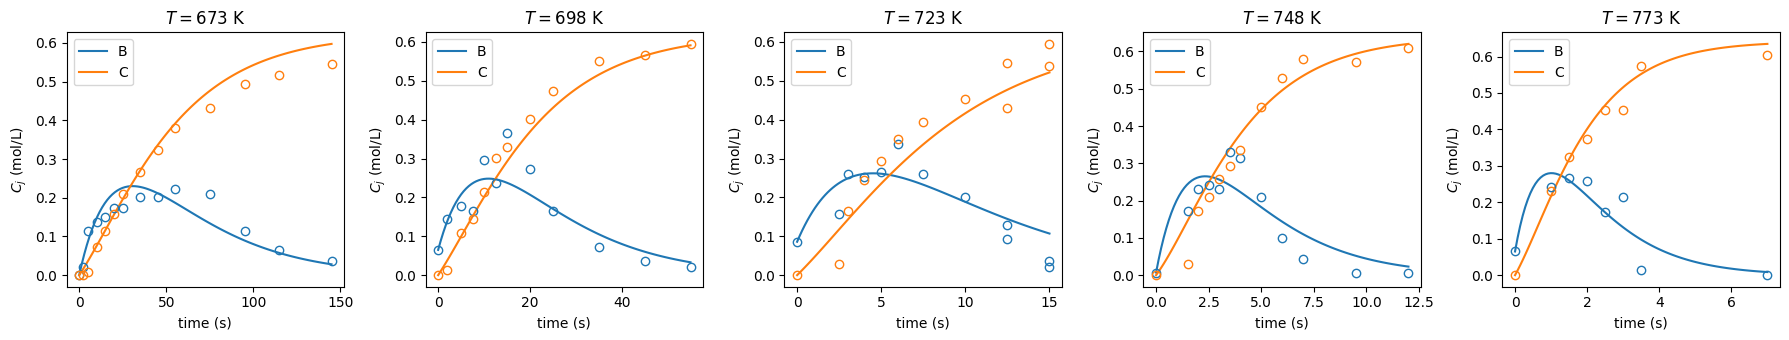

In [17]:
tic = time.perf_counter()
result_all = minimize(sse_all, param_seed_all, method='L-BFGS-B', options={'eps': 1e-6})  # [blank] minimize sse_all from param_seed_all with L-BFGS-B (options={'eps': 1e-6})
optim_params = result_all.x

print(result_all.message)
print('SSE: %.4e after %i iterations (%i model evaluations), %.0f s'
      % (result_all.fun, result_all.nit, result_all.nfev, time.perf_counter() - tic))

kin_fit = make_kinetics(optim_params)
fig, axes = plt.subplots(1, len(temps), figsize=(18, 3.5))
for exp_name, ax in zip(x_data, axes):
    plot_fit(x_data[exp_name], y_data[exp_name], kin_fit, ax=ax, **exp_inputs[exp_name])
fig.tight_layout()
plt.show()

### Confidence intervals

For a least-squares problem, the covariance of the estimates is approximated from the Jacobian of the residuals, $J_{ip} = \partial r_i / \partial \theta_p$, at the optimum:

$$ \mathrm{Cov}(\hat\theta) \approx s^2 \left(J^T J\right)^{-1}, \qquad s^2 = \frac{SSE}{n_{data} - n_{params}} $$

and the $(1-\alpha)$ confidence intervals are $\hat\theta_p \pm t_{1-\alpha/2,\, n_{data} - n_{params}} \sqrt{\mathrm{Cov}_{pp}}$. We build $J$ column by column with finite differences.

                estimate  95% CI (+/-)  95% CI (%)
\varphi_{1, 1}   -2.0228        0.1548      7.6543
\varphi_{1, 2}   -3.3322        0.4220     12.6645
\varphi_{1, 3}   -2.1558        0.2494     11.5704
\varphi_{1, 4}   -2.2965        0.1432      6.2366
\varphi_{2, 1}    9.8070        0.1169      1.1921
\varphi_{2, 2}    9.6873        0.3118      3.2184
\varphi_{2, 3}    9.7701        0.1782      1.8241
\varphi_{2, 4}    9.6840        0.1306      1.3485


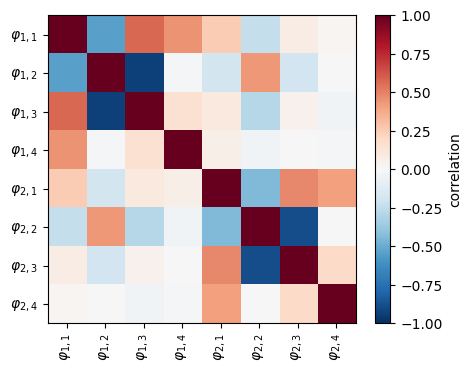

In [18]:
from scipy.stats import t as t_dist

resid_opt = residuals_all(optim_params)
jac = np.zeros((len(resid_opt), len(optim_params)))
for p in range(len(optim_params)):
    step = 1e-5 * max(1, abs(optim_params[p]))
    params_pert = optim_params.copy()
    params_pert[p] += step
    jac[:, p] = (residuals_all(params_pert) - resid_opt) / step  # [blank] finite-difference column p of the Jacobian

# [adv-start] degrees of freedom 'dof', variance 's2', covariance 'covar' and 95% half-widths 'half_width' (formulas above; use t_dist.ppf)
dof = len(resid_opt) - len(optim_params)
s2 = resid_opt @ resid_opt / dof
covar = s2 * np.linalg.inv(jac.T @ jac)
half_width = t_dist.ppf(0.975, dof) * np.sqrt(np.diag(covar))
# [adv-end]

intervals = pd.DataFrame({'estimate': optim_params, '95% CI (+/-)': half_width,
                          '95% CI (%)': 100 * half_width / np.abs(optim_params)}, index=names_all)
print(intervals.round(4))

correlation = covar / np.outer(np.sqrt(np.diag(covar)), np.sqrt(np.diag(covar)))  # [adv] correlation matrix from the covariance
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(names_all)), ['$%s$' % name for name in names_all], rotation=90)
ax.set_yticks(range(len(names_all)), ['$%s$' % name for name in names_all])
fig.colorbar(im, label='correlation')
plt.show()

Let's go back to the original parameters, run the model at the optimum, and compare with one dataset.

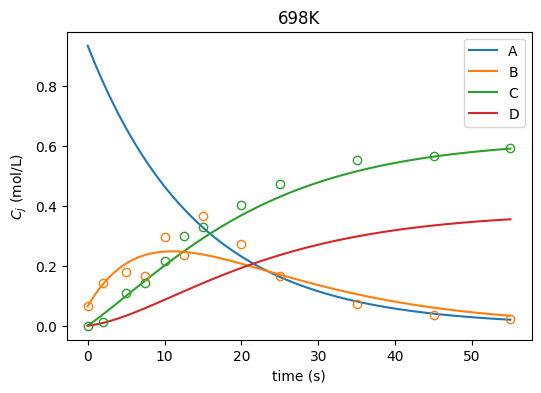

In [19]:
# [adv-start] back to the plain Arrhenius parameters k_optim (A_i) and ea_optim (E_i, J/mol), for both values of 'reformulate'
if reformulate:
    ea_optim = np.exp(optim_params[4:]) * 8.314
    k_optim = np.exp(ea_optim / 8.314 / temp_mean + optim_params[:4])
else:
    k_optim = optim_params[:4]
    ea_optim = optim_params[4:]
# [adv-end]

kin_optim = RxnKinetics(path_pure, rxn_list=rxns, k_params=k_optim, ea_params=ea_optim)  # [blank] kinetics with k_optim and ea_optim (plain Arrhenius)

temp_str = '698K'
t_fine = np.linspace(0, x_data[temp_str][-1], 100)
c_model = simulate(kin_optim, t_fine, **exp_inputs[temp_str])  # [adv] model concentrations at t_fine for this experiment

fig, ax = plt.subplots(figsize=(6, 4))
lines = ax.plot(t_fine, c_model[:, :4])
ax.legend(lines, ['A', 'B', 'C', 'D'])

# measured B and C with the colors of their model lines
for line, measured in zip(lines[1:3], y_data[temp_str].T):
    ax.plot(x_data[temp_str], measured, 'o', mfc='None', color=line.get_color())

ax.set_xlabel('time (s)')
ax.set_ylabel('$C_j$ (mol/L)')
ax.set_title(temp_str)
plt.show()

Finally, the optimum parameters can be compiled in a pandas dataframe:

In [20]:
optim_df = pd.DataFrame(np.column_stack((np.log(k_optim), ea_optim / 8.314)),
                        columns=('ln(A_optim)', 'Ea_optim/R'), index=rxns)
print(optim_df)

         ln(A_optim)    Ea_optim/R
A --> B    23.094615  18159.918550
A --> C    18.951543  16111.165267
B --> C    22.053221  17503.152119
B --> D    19.913590  16057.873548


**Things to try**
* Set `reformulate = False` and compare the number of iterations and the confidence intervals.
* Replace `L-BFGS-B` by `Nelder-Mead` in the first stage. How many model evaluations does it need?
* Use the poor seeds (`k_seed = [1e5] * 4`, `ea_seed = [1e5] * 4`). Does the second stage still converge?
* Remove the bounds in the first stage. How long do the fits take now, and why?